# Heisenberg quench: emu-mps vs exact Chebyshev propagation (Gershgorin / Lanczos bounds)

We evolve the noiseless Heisenberg Hamiltonian (convention of `examples/emu_mps/heisenberg.py`)

$$H = \sum_i \frac{\Omega_i}{2} X_i - \sum_i \Delta_i n_i + \sum_{i<j} J^{xx}_{ij} X_iX_j + J^{yy}_{ij} Y_iY_j + J^{zz}_{ij} Z_iZ_j, \qquad n = \tfrac{1-Z}{2}$$

from $|0\dots0\rangle$ with a **constant** drive, and compare wall time and accuracy of three solvers on one GPU.

| Solver | What it is | Error | Cost / memory |
|---|---|---|---|
| **emu-mps** | Matrix product state, TDVP time stepping (`dt` = 10 ns) | approximate: SVD truncation (`precision`), bond-dimension cap, TDVP projection | $\propto n\,\chi^3$ per step, memory $\propto n\chi^2$: many qubits if entanglement stays low |
| **Chebyshev, Gershgorin bounds** (`scripts/heisenberg_cheb_fast.py`, default) | exact state vector, Chebyshev series of $e^{-iHt}$ | ~1e-14 (round-off) | $\propto 2^n \times$ (number of terms), memory $\propto 2^n$: $n \lesssim 27$ on a 40 GB A100 |
| **Chebyshev, Lanczos bounds** (`bounds="lanczos"`) | same series, tighter spectral interval | same, guarded (see below) | fewer terms, + 60 matvecs |

## How the Chebyshev method works

Rescale $H$ so that its spectrum lies in $[-1, 1]$: $\tilde H = (H - c)/w$, where $[c - w,\, c + w]$ contains every eigenvalue. Then (Jacobi–Anger expansion)

$$e^{-iHt}|\psi_0\rangle = e^{-ict} \sum_{k\ge 0} (2-\delta_{k0})\,(-i)^k J_k(wt)\; T_k(\tilde H)|\psi_0\rangle ,$$

with $J_k$ Bessel functions and $T_k$ Chebyshev polynomials, computed by the three-term recurrence $T_{k+1} = 2\tilde H T_k - T_{k-1}$: **one Hamiltonian–vector product (matvec) per term**. Only the scalar coefficients depend on $t$, so one series gives every output time. $J_k(wt)$ dies off quickly once $k > wt$, so the number of terms is

$$K \approx w\,t + O\big((wt)^{1/3}\big).$$

**The cost is proportional to the half-width $w$ of the interval.** It must contain the spectrum: on $[-1,1]$, $|T_k(x)| \le 1$, but outside it $T_k$ grows like $\cosh(k s)$ and the recurrence blows up. Finding a tight $[c-w, c+w]$ cheaply is therefore the whole game. The two options are:

### Gershgorin bounds (default, rigorous)
**Gershgorin circle theorem**: every eigenvalue of a matrix lies in a disc centred at some diagonal entry $H_{xx}$ with radius $R_x = \sum_{y\ne x} |H_{xy}|$ (the off-diagonal row sum). For a real symmetric $H$ the discs are intervals, so

$$\operatorname{spec}(H) \subset \big[\min_x (H_{xx} - R_x),\; \max_x (H_{xx} + R_x)\big].$$

Here every row has the same off-diagonal content: $|\Omega_i|/2$ for each single flip, and $|J^{xx}-J^{yy}|$ or $|J^{xx}+J^{yy}|$ for each pair flip. So $R = \sum_i |\Omega_i|/2 + \sum_{i<j}\max(|J^{xx}_{ij}-J^{yy}_{ij}|, |J^{xx}_{ij}+J^{yy}_{ij}|)$, and the bound costs one pass over the diagonal. It is **guaranteed but loose**: it assumes that the largest diagonal entry and the full off-diagonal weight add up, which they never do exactly.

### Lanczos bounds (opt-in, tighter, guarded)
Run 60 **Lanczos** steps from a random vector. This builds a $60\times60$ tridiagonal matrix (the projection of $H$ onto a Krylov subspace), whose extreme eigenvalues (*Ritz values*) converge very fast to the extreme eigenvalues of $H$, **from inside**. The interval is widened by 1 % of its half-width to cover what has not converged yet. The cost is 60 matvecs. A Ritz value is not a proof, so the series carries a **guard**: with a valid interval, $\|T_k|\psi_0\rangle\| \le 1$ for every $k$. The code checks $\|T_k\|^2 \le 1 + 10^{-9}$ during the series and, if that fails, restarts with Gershgorin bounds (`stats["lanczos_rejected"]`).

Lanczos pays off when the saved terms $(w_G - w_L)\,t$ exceed 60, i.e. for long times or loose Gershgorin bounds.


*Executed on pasqal-dgx (one A100-SXM4-40GB, torch 2.10 + Triton 3.6, emu-mps from this repo) with `jupyter nbconvert --execute`, job 1693332, 2026-10-25; total 20 min, almost all emu-mps. emu-mps runs on the GPU (`gpu=None` selects it when one is available).*

In [1]:
import logging
import time
import warnings
from functools import reduce

import matplotlib.pyplot as plt
import numpy as np
import scipy.sparse as sp
import torch
from emu_base import HamiltonianType, SequenceData
from emu_mps import MPSBackend, MPSConfig, StateResult

import heisenberg_cheb_fast as hcf

device = "cuda" if torch.cuda.is_available() else "cpu"
print(torch.cuda.get_device_name() if device == "cuda" else "CPU", "| torch", torch.__version__)
warnings.filterwarnings("ignore", message="long double is float64")  # macOS only; Linux has 80-bit long double

plt.rcParams.update({  # Sokolov style (fonts fall back to sans-serif where Avenir Next is missing)
    "font.family": ["Avenir Next", "Avenir", "Arial", "sans-serif"], "font.size": 9, "mathtext.fontset": "stix",
    "axes.spines.top": False, "axes.spines.right": False, "axes.linewidth": 0.8, "legend.frameon": False,
    "lines.linewidth": 1.5, "lines.markersize": 5, "figure.dpi": 130, "figure.constrained_layout.use": True,
})
BLUE, GREEN, GREY = "#0070C0", "#00B050", "#7F7F7F"  # blue = Chebyshev (ours), green = emu-mps (baseline)
STYLE = {  # method -> plot style
    "cheb gershgorin": dict(color=BLUE, ls="-", marker="o", label="Chebyshev, Gershgorin"),
    "cheb lanczos": dict(color=BLUE, ls="--", marker="s", mfc="white", label="Chebyshev, Lanczos"),
    "mps 1e-05": dict(color=GREEN, ls="--", marker="^", mfc="white", label="emu-mps, precision 1e-5"),
    "mps 1e-10": dict(color=GREEN, ls="-", marker="v", label="emu-mps, precision 1e-10"),
}

# Model: XYZ chain with open boundaries, uniform constant drive (rad/us), as heisenberg.py.
JXX, JYY, JZZ = 1.0, 0.7, 1.3
OMEGA, DELTA = 2.0, 1.0
T_NS, DT_NS, N_OUT = 2000, 10, 11  # total time, emu-mps step, output times (every 200 ns)
times_us = np.linspace(0, T_NS / 1000, N_OUT)
N_LIST = [8, 10, 12, 14, 16, 18, 20, 22, 24]
MPS_PRECISIONS = [1e-5, 1e-10]  # 1e-5 is the emu-mps default
N_DENSE_MAX = 12  # dense diagonalisation reference up to here; above it, Chebyshev-Gershgorin is the reference
MPS_TIME_CAP = 600  # s: an emu-mps setting is skipped at larger n once one run takes longer

NVIDIA A100-SXM4-40GB | torch 2.10.0+cu128


## Solvers

`run_cheb` and `run_mps` return the wall time (GPU synchronised) and the states at all `N_OUT` output times as dense vectors (the MPS is contracted after the timer stops). `dense_states` is an independent reference: $H$ is built from Kronecker products of Pauli matrices (not from the bit tricks of the Chebyshev code) and diagonalised exactly.

In [2]:
def sync():
    if device == "cuda":
        torch.cuda.synchronize()


def chain(n):
    c = np.diag(np.ones(n - 1), 1)
    c = c + c.T
    return np.stack([JXX * c, JYY * c, JZZ * c])


def run_cheb(n, bounds):
    stats = {}
    sync()
    t0 = time.perf_counter()
    psi = hcf.evolve(chain(n)[None], np.full((1, n), OMEGA), np.full((1, n), DELTA), times_us, device=device,
                     output="state", bounds=bounds, stats=stats)
    sync()
    return time.perf_counter() - t0, psi[:, 0], stats


def run_mps(n, precision):
    nsteps = T_NS // DT_NS
    c128 = torch.complex128
    seq = SequenceData(
        omega=torch.full((nsteps, n), OMEGA, dtype=c128),
        delta=torch.full((nsteps, n), DELTA, dtype=c128),
        phi=torch.zeros(nsteps, n, dtype=c128),
        interaction_matrix=lambda t: torch.tensor(chain(n)),  # 3 x n x n => Heisenberg
        qubit_ids=tuple(f"q{i}" for i in range(n)),
        bad_atoms=(False,) * n,
        lindblad_ops=[],
        state_prep_error=0.0,
        target_times=[DT_NS * k for k in range(nsteps + 1)],
        eigenstates=["0", "1"],
        hamiltonian_type=HamiltonianType.XY,
        has_stochastic_noise=False,
    )
    config = MPSConfig(observables=[StateResult(evaluation_times=list(np.linspace(0, 1, N_OUT)))],
                       optimize_qubit_ordering=False, precision=precision, log_level=logging.WARNING)
    sync()
    t0 = time.perf_counter()
    res = MPSBackend._run_from_sequence_data(seq, config)
    sync()
    elapsed = time.perf_counter() - t0
    chi = max(f.shape[2] for f in res.state[-1].factors[:-1])
    psi = torch.stack([reduce(lambda a, b: torch.tensordot(a, b, dims=1), [f.to(device) for f in m.factors]).reshape(-1)
                       for m in res.state])
    return elapsed, psi, chi


def dense_hamiltonian(n):
    X = sp.csr_matrix([[0, 1], [1, 0]], dtype=complex)
    Y = sp.csr_matrix([[0, -1j], [1j, 0]])
    Z = sp.csr_matrix([[1, 0], [0, -1]], dtype=complex)
    N = sp.csr_matrix([[0, 0], [0, 1]], dtype=complex)

    def op(single, i):
        return reduce(lambda a, b: sp.kron(a, b, format="csr"), [single if k == i else sp.eye(2) for k in range(n)])

    J = chain(n)
    H = sum(OMEGA / 2 * op(X, i) - DELTA * op(N, i) for i in range(n))
    H = H + sum(J[a, i, j] * op(P, i) @ op(P, j)
                for a, P in enumerate((X, Y, Z)) for i in range(n) for j in range(i + 1, n) if J[a, i, j])
    H = H.toarray()
    assert np.abs(H.imag).max() == 0  # Y_i Y_j is real: H is real symmetric
    return H.real


def dense_states(n):
    E, V = np.linalg.eigh(dense_hamiltonian(n))
    psi = V @ (np.exp(-1j * np.outer(E, times_us)) * V[0][:, None])  # V^T |0...0> = first row of V
    return torch.as_tensor(psi.T, device=device), (E[0], E[-1])


def infidelity(ref, psi):  # 1 - |<ref(t)|psi(t)>|^2 at every output time
    return (1 - (ref.conj() * psi).sum(-1).abs() ** 2).abs().cpu().numpy()  # abs: round-off gives +/- 1e-15

## What the two bounds look like

Exact spectrum (dense diagonalisation, $n = 10$) against the intervals $[c-w, c+w]$ used by the series. The number of Chebyshev terms is roughly $w\,t$.

gershgorin: [ -42.000,   37.000] rad/us, half-width w = 39.500, series matvecs = 126, Lanczos matvecs = 0
lanczos   : [ -23.308,   16.481] rad/us, half-width w = 19.895, series matvecs = 77, Lanczos matvecs = 60
exact     : [ -23.111,   16.284] rad/us, half-width 19.698


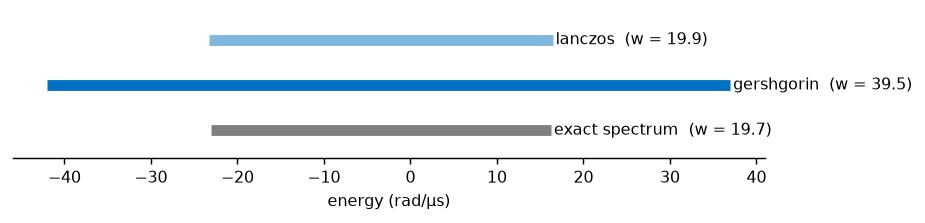

In [3]:
n = 10
_, (e_min, e_max) = dense_states(n)
intervals = {"exact spectrum": (e_min, e_max)}
for bounds in ("gershgorin", "lanczos"):
    _, _, s = run_cheb(n, bounds)
    intervals[bounds] = (s["center"] - s["half_width"], s["center"] + s["half_width"])
    print(f"{bounds:10s}: [{intervals[bounds][0]:8.3f}, {intervals[bounds][1]:8.3f}] rad/us, half-width "
          f"w = {s['half_width']:6.3f}, series matvecs = {s['matvecs']}, Lanczos matvecs = {s['lanczos_matvecs']}")
print(f"exact     : [{e_min:8.3f}, {e_max:8.3f}] rad/us, half-width {0.5 * (e_max - e_min):6.3f}")

fig, ax = plt.subplots(figsize=(7, 1.6))
for y, (name, (lo, hi)) in enumerate(intervals.items()):
    color = {"exact spectrum": GREY, "gershgorin": BLUE, "lanczos": BLUE}[name]
    ax.plot([lo, hi], [y, y], color=color, lw=6, solid_capstyle="butt", alpha=1 if name != "lanczos" else 0.5)
    ax.text(hi + 0.3, y, f"{name}  (w = {0.5 * (hi - lo):.1f})", va="center")
ax.set_yticks([])
ax.spines["left"].set_visible(False)
ax.set_xlabel("energy (rad/µs)")
ax.set_ylim(-0.6, 2.6)
plt.show()

## Benchmark

For every $n$: both Chebyshev variants, then emu-mps at two precisions. Warm-up first, so that the Triton compilation and CUDA initialisation are not timed. Errors are the infidelity $1 - |\langle\psi_\text{ref}(t)|\psi(t)\rangle|^2$, maximised over the output times. Reference: dense diagonalisation for $n \le 12$, Chebyshev-Gershgorin above (which agrees with the dense result to ~1e-15 where both exist).

In [4]:
run_cheb(8, "gershgorin"), run_cheb(8, "lanczos"), run_mps(8, 1e-5)  # warm-up

rows, curves, skipped = [], {}, set()
for n in N_LIST:
    ref = dense_states(n)[0] if n <= N_DENSE_MAX else None
    runs = {}
    for bounds in ("gershgorin", "lanczos"):
        sec, psi, s = run_cheb(n, bounds)
        runs[f"cheb {bounds}"] = (sec, psi, dict(matvecs=s["matvecs"] + s["lanczos_matvecs"], w=float(s["half_width"]),
                                                 bounds_used=s["bounds_used"]))
    for p in MPS_PRECISIONS:
        if p in skipped:
            continue
        sec, psi, chi = run_mps(n, p)
        runs[f"mps {p:.0e}"] = (sec, psi, dict(chi=chi))
        if sec > MPS_TIME_CAP:
            skipped.add(p)
    if ref is None:
        ref = runs["cheb gershgorin"][1]
    for name, (sec, psi, info) in runs.items():
        inf = infidelity(ref, psi) if not (name == "cheb gershgorin" and n > N_DENSE_MAX) else np.full(N_OUT, np.nan)
        curves[name, n] = inf
        rows.append(dict(method=name, n=n, seconds=sec, max_infidelity=np.nanmax(inf) if n <= N_DENSE_MAX or
                         name != "cheb gershgorin" else np.nan, **info))
        print(f"n={n:2d}  {name:16s} {sec:8.2f} s   max infidelity {rows[-1]['max_infidelity']:9.1e}   {info}")
    del runs, ref, psi
    if device == "cuda":
        torch.cuda.empty_cache()

emu-mps allows only {'statistics', 'occupation', 'energy_second_moment', 'correlation_matrix', 'energy', 'energy_variance', 'bitstrings'} observables with `optimize_qubit_ordering = True`. you provided unsupported {'state'} using `optimize_qubit_ordering = False` instead.


emu-mps allows only {'statistics', 'occupation', 'energy_second_moment', 'correlation_matrix', 'energy', 'energy_variance', 'bitstrings'} observables with `optimize_qubit_ordering = True`. you provided unsupported {'state'} using `optimize_qubit_ordering = False` instead.


Requested Lanczos convergence tolerance (precision * extra_krylov_tolerance = 1.00e-13) is below minimum threshold 1.00e-12. Automatically adjusting extra_krylov_tolerance from 1.00e-03 to 1.00e-02 to maintain numerical stability.


emu-mps allows only {'statistics', 'occupation', 'energy_second_moment', 'correlation_matrix', 'energy', 'energy_variance', 'bitstrings'} observables with `optimize_qubit_ordering = True`. you provided unsupported {'state'} using `optimize_qubit_ordering = False` instead.


n= 8  cheb gershgorin      0.02 s   max infidelity   1.8e-15   {'matvecs': 105, 'w': 31.0, 'bounds_used': 'gershgorin'}
n= 8  cheb lanczos         0.03 s   max infidelity   1.3e-15   {'matvecs': 126, 'w': 15.69438419921669, 'bounds_used': 'lanczos'}
n= 8  mps 1e-05           19.41 s   max infidelity   7.4e-07   {'chi': 16}
n= 8  mps 1e-10           27.62 s   max infidelity   2.1e-14   {'chi': 16}


...

n=22  cheb gershgorin      0.60 s   max infidelity       nan   {'matvecs': 242, 'w': 90.5, 'bounds_used': 'gershgorin'}
n=22  cheb lanczos         0.26 s   max infidelity   2.7e-15   {'matvecs': 198, 'w': 44.750898143591655, 'bounds_used': 'lanczos'}
n=22  mps 1e-05           75.82 s   max infidelity   1.5e-05   {'chi': 37}
n=22  mps 1e-10          116.19 s   max infidelity   1.9e-11   {'chi': 262}


emu-mps allows only {'statistics', 'occupation', 'energy_second_moment', 'correlation_matrix', 'energy', 'energy_variance', 'bitstrings'} observables with `optimize_qubit_ordering = True`. you provided unsupported {'state'} using `optimize_qubit_ordering = False` instead.


Requested Lanczos convergence tolerance (precision * extra_krylov_tolerance = 1.00e-13) is below minimum threshold 1.00e-12. Automatically adjusting extra_krylov_tolerance from 1.00e-03 to 1.00e-02 to maintain numerical stability.


emu-mps allows only {'statistics', 'occupation', 'energy_second_moment', 'correlation_matrix', 'energy', 'energy_variance', 'bitstrings'} observables with `optimize_qubit_ordering = True`. you provided unsupported {'state'} using `optimize_qubit_ordering = False` instead.


n=24  cheb gershgorin      1.27 s   max infidelity       nan   {'matvecs': 261, 'w': 99.0, 'bounds_used': 'gershgorin'}
n=24  cheb lanczos         1.14 s   max infidelity   4.4e-16   {'matvecs': 208, 'w': 48.93578883545015, 'bounds_used': 'lanczos'}
n=24  mps 1e-05           83.46 s   max infidelity   1.7e-05   {'chi': 37}
n=24  mps 1e-10          129.40 s   max infidelity   2.3e-11   {'chi': 291}


## Wall time and accuracy vs system size

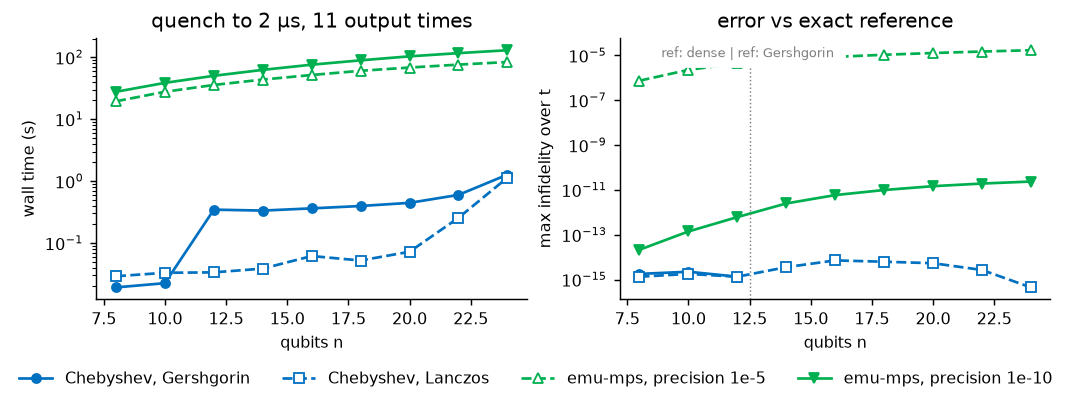

In [5]:
fig, (ax_t, ax_e) = plt.subplots(1, 2, figsize=(8, 3))
FLOOR = 1e-16  # infidelities at round-off are drawn at this floor (they can be ~ +/- 1e-15)
for name, style in STYLE.items():
    rs = [r for r in rows if r["method"] == name]
    ax_t.semilogy([r["n"] for r in rs], [r["seconds"] for r in rs], **style)
    rs = [r for r in rs if not np.isnan(r["max_infidelity"])]
    ax_e.semilogy([r["n"] for r in rs], [max(r["max_infidelity"], FLOOR) for r in rs], **style)
ax_t.set(xlabel="qubits n", ylabel="wall time (s)", title=f"quench to {T_NS / 1000:g} µs, {N_OUT} output times")
ax_e.set(xlabel="qubits n", ylabel="max infidelity over t", title="error vs exact reference")
ax_e.axvline(N_DENSE_MAX + 0.5, color=GREY, lw=0.8, ls=":")
ax_e.text(N_DENSE_MAX + 0.5, 0.97, "ref: dense | ref: Gershgorin ", fontsize=7, color=GREY, ha="center", va="top",
          transform=ax_e.get_xaxis_transform(), backgroundcolor="white")
fig.legend(*ax_t.get_legend_handles_labels(), loc="outside lower center", ncol=4)
plt.show()

## Error along the trajectory

Infidelity vs time for the largest $n$ where emu-mps ran at both precisions. emu-mps errors accumulate step by step (truncation); the Chebyshev error stays at round-off.

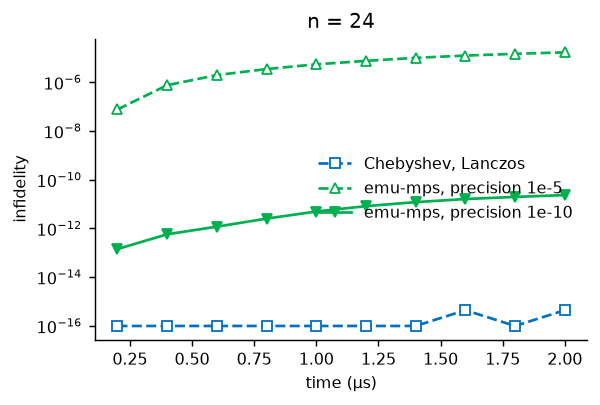

In [6]:
n_show = max(n for (name, n) in curves if name == f"mps {MPS_PRECISIONS[-1]:.0e}")
fig, ax = plt.subplots(figsize=(4.5, 3))
for name, style in STYLE.items():
    inf = curves.get((name, n_show))
    if inf is not None and not np.isnan(inf).all():
        ax.semilogy(times_us[1:], np.maximum(inf[1:], FLOOR), **style)
ax.set(xlabel="time (µs)", ylabel="infidelity", title=f"n = {n_show}")
ax.legend(loc="center right")
plt.show()

## Gershgorin vs Lanczos: work done

Total matvecs (Lanczos includes its 60 setup steps) and the half-width $w$ of each interval.

In [7]:
print(f"{'n':>3} {'w Gersh':>8} {'w Lanczos':>9} {'matvecs G':>9} {'matvecs L':>9} {'time G (s)':>10} "
      f"{'time L (s)':>10} {'L used':>8}")
for n in N_LIST:
    g = next(r for r in rows if r["method"] == "cheb gershgorin" and r["n"] == n)
    lz = next(r for r in rows if r["method"] == "cheb lanczos" and r["n"] == n)
    print(f"{n:3d} {g['w']:8.2f} {lz['w']:9.2f} {g['matvecs']:9d} {lz['matvecs']:9d} {g['seconds']:10.3f} "
          f"{lz['seconds']:10.3f} {lz['bounds_used']:>8}")
print("\nemu-mps final bond dimension:", {(r["method"], r["n"]): r["chi"] for r in rows if r["method"].startswith("mps")})

  n  w Gersh w Lanczos matvecs G matvecs L time G (s) time L (s)   L used
  8    31.00     15.69       105       126      0.019      0.029  lanczos
 10    39.50     19.89       126       137      0.022      0.033  lanczos
 12    48.00     24.06       146       148      0.346      0.034  lanczos
 14    56.50     28.21       166       159      0.334      0.039  lanczos
 16    65.00     32.34       185       169      0.363      0.062  lanczos
 18    73.50     36.47       204       179      0.396      0.052  lanczos
 20    82.00     40.59       223       188      0.445      0.072  lanczos
 22    90.50     44.75       242       198      0.598      0.255  lanczos
 24    99.00     48.94       261       208      1.270      1.136  lanczos

emu-mps final bond dimension: {('mps 1e-05', 8): 16, ('mps 1e-10', 8): 16, ('mps 1e-05', 10): 24, ('mps 1e-10', 10): 32, ('mps 1e-05', 12): 31, ('mps 1e-10', 12): 64, ('mps 1e-05', 14): 34, ('mps 1e-10', 14): 128, ('mps 1e-05', 16): 37, ('mps 1e-10', 16): 209

## Observations

**Accuracy.** Both Chebyshev variants stay at round-off at every $n$: infidelity $\le 7\times10^{-15}$ against dense diagonalisation ($n \le 12$) and against each other above. emu-mps is controlled by `precision`:
- At `precision` = 1e-5 (the default), the bond dimension saturates at $\chi = 37$ and the infidelity grows from $7\times10^{-7}$ ($n=8$) to $1.7\times10^{-5}$ ($n=24$), accumulating along the trajectory.
- At 1e-10, $\chi$ reaches 291 and the infidelity stays $\le 2.3\times10^{-11}$.

**Time.** On the same A100, Chebyshev takes 0.02–1.3 s against 19–129 s for emu-mps, i.e. 60× to over 1000× faster for $n \le 24$. The scalings differ:
- **emu-mps:** grows roughly linearly in $n$ here, because entanglement stays low up to 2 µs. Most of its time for small $n$ is per-step overhead (200 TDVP steps of small tensors on a GPU).
- **Chebyshev:** grows like $2^n$ and hits the 40 GB memory limit at $n \approx 27$. Beyond that, or for longer, weakly entangled evolutions, emu-mps is the only option.

**Gershgorin timings at $n = 12$–$20$ (~0.35 s) are an artefact.** The Triton kernel is compiled once per $n$ (`N_BITS` is a compile-time constant), and Gershgorin ran first at each $n$. A separate warm run (same quench, second call at each $n$) gives:

| $n$ | Gershgorin, 1st call | Gershgorin, warm | Lanczos, warm |
|---|---|---|---|
| 12 | 1.70 s | 0.022 s | 0.033 s |
| 16 | 0.33 s | 0.027 s | 0.045 s |
| 20 | 0.41 s | 0.057 s | 0.076 s |
| 24 | 1.22 s | 0.83 s | 1.15 s |

**Gershgorin vs Lanczos.** The Gershgorin interval is twice as wide as the true spectrum: at $n=10$, $w = 39.5$ against an exact $19.7$, while Lanczos gives $19.9$. So Lanczos roughly halves the series. For this short quench (2 µs) that saves only $(w_G - w_L)\,t \approx 30$–$100$ terms, which the 60 Lanczos setup steps mostly cancel. Total matvecs are lower with Lanczos only from $n = 14$, and the warm wall time is lower with Gershgorin at every $n$. At $n = 24$, Lanczos is slower despite 20 % fewer matvecs, so its setup has a cost beyond the matvecs (the diagonal is rebuilt; not profiled). Lanczos wins for long evolutions: the saving grows like $w_L t$ while the setup stays fixed. Example: the earlier 4 µs run at $n=26$ used 277 vs 511 series matvecs.

**Rule of thumb:** keep the default Gershgorin bounds for short quenches; use `bounds="lanczos"` when $w_L\,t \gg 60$, i.e. long times or strong couplings.